In [1]:
# Recurrent Neural Networks (RNN) - sequences, hidden state, vanishing gradients
# Dataset: SMS Spam Collection (the Kaggle spam.csv you already downloaded)
#          ../Datasets/spam.csv
#
# Needs: pip install tensorflow
#
# Why RNNs? A normal network sees a fixed-size input all at once. Text is a SEQUENCE:
# word order matters and messages have different lengths. An RNN reads one word at a
# time and carries a "memory" (the hidden state) from each word to the next.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)


C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/

In [2]:
# ============================================================
# PART 1 - An RNN by hand: the whole idea in a few lines of NumPy
# ============================================================
# At every time step t the RNN does:   h_t = tanh( x_t @ Wx + h_(t-1) @ Wh + b )
#   x_t     = the current input (one word, as a vector of numbers)
#   h_(t-1) = the memory from the previous step
#   h_t     = the new memory, passed on to the next step

input_dim = 3       # size of each word vector
hidden_dim = 4      # size of the memory
seq_len = 5         # number of words in our tiny "sentence"

Wx = np.random.randn(input_dim, hidden_dim) * 0.5     # input  -> hidden weights
Wh = np.random.randn(hidden_dim, hidden_dim) * 0.5    # hidden -> hidden weights (the "recurrent" part)
b = np.zeros(hidden_dim)

sentence = np.random.randn(seq_len, input_dim)        # 5 random "word vectors"

h = np.zeros(hidden_dim)                              # memory starts empty
for t in range(seq_len):
    h = np.tanh(sentence[t] @ Wx + h @ Wh + b)
    print(f"Step {t}: hidden state = {np.round(h, 3)}")

# the SAME Wx, Wh and b are reused at every step (weight sharing across time) -
# that is how one small set of weights can handle sentences of any length.
# the final h is a summary of the whole sentence; a Dense layer on top can classify it.


Step 0: hidden state = [ 0.026 -0.087 -0.278 -0.405]
Step 1: hidden state = [ 0.581 -0.416  0.791  0.95 ]
Step 2: hidden state = [ 0.717 -0.474 -0.918 -0.144]
Step 3: hidden state = [-0.594 -0.309 -0.969 -0.859]
Step 4: hidden state = [-0.199  0.446  0.908  0.917]


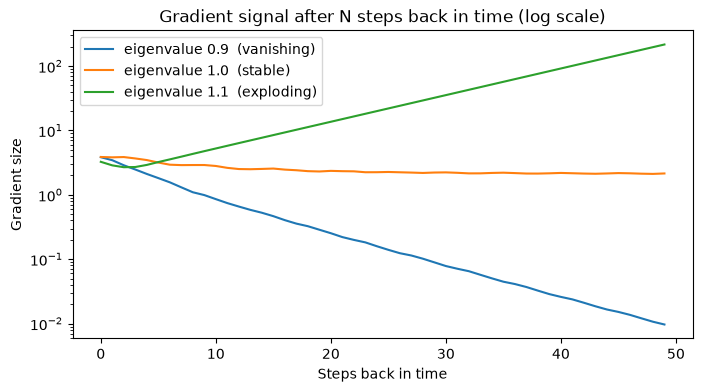

In [3]:
# ============================================================
# PART 2 - The vanishing gradient problem (why plain RNNs struggle)
# ============================================================
# Training an RNN pushes the error signal BACKWARDS through every time step,
# multiplying by the recurrent weights Wh at each step. Repeated multiplication either
# shrinks the signal toward zero (vanishing) or blows it up (exploding).

def gradient_norms(scale, steps=50, size=16):
    W = np.random.randn(size, size)
    W = W / np.abs(np.linalg.eigvals(W)).max() * scale     # rescale so the largest eigenvalue = scale
    grad = np.eye(size)
    norms = []
    for _ in range(steps):
        grad = grad @ W
        norms.append(np.linalg.norm(grad))
    return norms

plt.figure(figsize=(8, 4))
plt.semilogy(gradient_norms(0.9), label="eigenvalue 0.9  (vanishing)")
plt.semilogy(gradient_norms(1.0), label="eigenvalue 1.0  (stable)")
plt.semilogy(gradient_norms(1.1), label="eigenvalue 1.1  (exploding)")
plt.title("Gradient signal after N steps back in time (log scale)")
plt.xlabel("Steps back in time")
plt.ylabel("Gradient size")
plt.legend()
plt.show()

# with a value below 1 the signal from early words has almost vanished by step 50,
# so the network cannot learn long-range patterns. The tanh function makes it even worse.
# LSTM and GRU (script 48) were designed to fix exactly this.

In [5]:
# ============================================================
# PART 3 - RNN text classifier on SMS spam
# ============================================================

df = pd.read_csv("../Datasets/spam.csv", encoding="latin-1")
df = df.iloc[:, :2]
df.columns = ["label", "message"]
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})

print(df.shape)
print(df["label"].value_counts())

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["message"].values, df["label_num"].values,
    test_size=0.2, random_state=42, stratify=df["label_num"]
)

# ---- Turn text into sequences of integer word IDs ----
# TextVectorization builds the vocabulary from TRAIN text only (no peeking at test data),
# keeps the 5000 most common words, and pads/cuts every message to exactly 40 words
MAX_WORDS = 5000
SEQ_LEN = 40

vectorizer = layers.TextVectorization(max_tokens=MAX_WORDS, output_sequence_length=SEQ_LEN)
vectorizer.adapt(X_train_text)

X_train = vectorizer(X_train_text).numpy()
X_test = vectorizer(X_test_text).numpy()

print("Example message :", X_train_text[0])
print("As word IDs     :", X_train[0])      # 0 = padding, 1 = unknown word
# ---- Class imbalance: spam is only ~13% of messages ----
# without help, a model can score ~87% accuracy by calling EVERYTHING ham.
# class weights make mistakes on spam count more during training.
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: weights[0], 1: weights[1]}
print("Class weights:", class_weight)

# ---- Build the model ----
model = keras.Sequential([
    layers.Input(shape=(SEQ_LEN,)),
    layers.Embedding(MAX_WORDS, 32),        # word ID -> a learnable 32-number vector
    layers.SimpleRNN(32),                   # reads the 40 words one by one, returns the final memory
    layers.Dense(1, activation="sigmoid")   # spam probability
])
model.summary()

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=32,
    class_weight=class_weight,
    verbose=0
)


(5572, 3)
label
ham     4825
spam     747
Name: count, dtype: int64
Example message : Going on nothing great.bye
As word IDs     : [ 74  19 306   1   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0]
Class weights: {0: np.float64(0.577481212749417), 1: np.float64(3.7265886287625416)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 40, 32)              │         160,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn (SimpleRNN)               │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 162,113 (633.25 KB)

 Trainable params: 162,113 (633.25 KB)

 Non-trainable params: 0 (0.00 B)

              precision    recall  f1-score   support

         ham       0.91      1.00      0.95       966
        spam       0.98      0.36      0.53       149

    accuracy                           0.91      1115
   macro avg       0.95      0.68      0.74      1115
weighted avg       0.92      0.91      0.90      1115



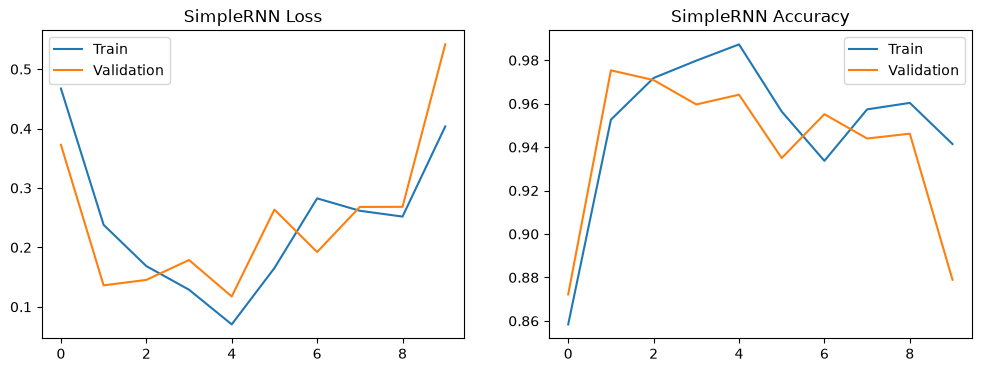

spam probability 0.95  ->  Congratulations! You have won a free prize, call now to claim
spam probability 0.40  ->  Are we still meeting for lunch tomorrow?


In [6]:
# ---- Evaluate - look at precision/recall for SPAM, not just accuracy ----
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=["ham", "spam"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="Train")
axes[0].plot(history.history["val_loss"], label="Validation")
axes[0].set_title("SimpleRNN Loss")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="Train")
axes[1].plot(history.history["val_accuracy"], label="Validation")
axes[1].set_title("SimpleRNN Accuracy")
axes[1].legend()
plt.show()

# ---- Try it on new messages ----
new_messages = np.array([
    "Congratulations! You have won a free prize, call now to claim",
    "Are we still meeting for lunch tomorrow?"
])
probs = model.predict(vectorizer(new_messages), verbose=0).ravel()
for msg, p in zip(new_messages, probs):
    print(f"spam probability {p:.2f}  ->  {msg}")

# short SMS messages are an easy case for a plain RNN. On longer text (reviews, articles)
# it gets much weaker, which is where LSTM and GRU in script 48 pull ahead.